<a href="https://colab.research.google.com/github/akshat280706/IP-LABS/blob/main/241080009_akshat_IP_Lab8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#akshat chauhan
#241080009
#IT

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Upload an image for object detection:


Saving yolo.jpeg to yolo.jpeg

0: 384x640 12 persons, 11 bicycles, 4 cars, 344.6ms
Speed: 8.6ms preprocess, 344.6ms inference, 25.8ms postprocess per image at shape (1, 3, 384, 640)

results:
object: person
score: 0.8841


object: car
score: 0.8808


object: person
score: 0.8556


object: person
score: 0.851


object: person
score: 0.7181


object: person
score: 0.6955


object: car
score: 0.6819


object: person
score: 0.6311


object: person
score: 0.6286


object: bicycle
score: 0.6242


object: car
score: 0.6082


object: person
score: 0.5844


object: person
score: 0.4943


object: bicycle
score: 0.479


object: bicycle
score: 0.4188


object: bicycle
score: 0.4121


object: bicycle
score: 0.3955


object: bicycle
score: 0.3844


object: car
score: 0.3806


object: person
score: 0.3767


object: bicycle
score: 0.3493


object: bicycle
score: 0.3372


object: person
score: 0.3057


object: bicycle
score: 0.2992


object: person
score: 0.2957


object: bicycle
score: 0.2563


object

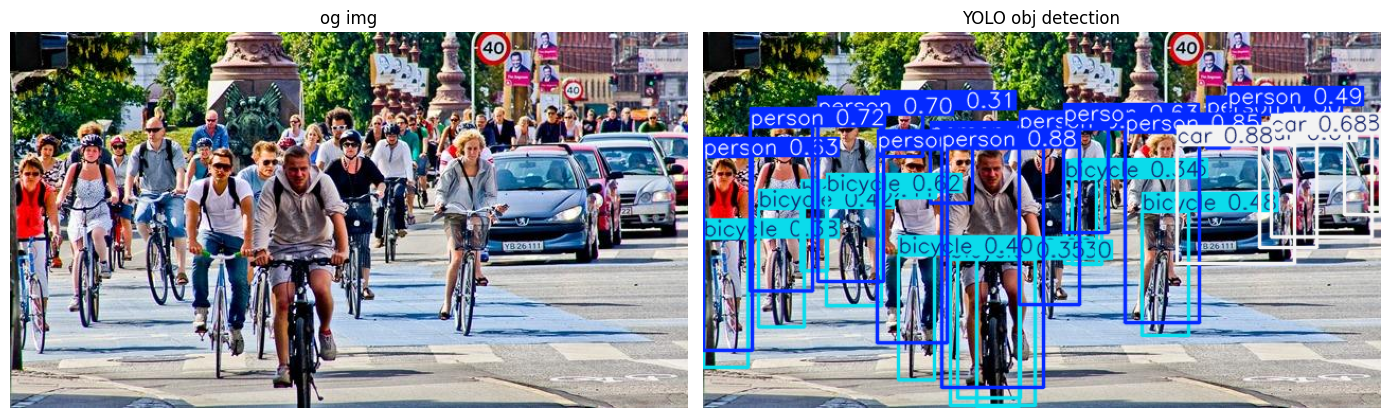

In [ ]:
import cv2
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import files
print("Upload an image for object detection:")
uploaded = files.upload()
image_path = next(iter(uploaded))
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Unable to read the uploaded image.")
model = YOLO("yolov8n.pt")

results = model(image)
print("\nresults:")
detected_count = 0

for result in results:
    for box in result.boxes:

        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        label = model.names[class_id]

        detected_count += 1

        print("object:", label)
        print("score:", round(confidence, 4))
        print("\n")

print("total detected objects:", detected_count)
annotated_image = results[0].plot()
original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

detected_rgb = cv2.cvtColor(annotated_image,cv2.COLOR_BGR2RGB)
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("og img")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(detected_rgb)
plt.title("YOLO obj detection")
plt.axis("off")

plt.tight_layout()
plt.show()